In [2]:
SELECT version() AS duckdb_version;
SELECT extension_name, installed, loaded, extension_version FROM duckdb_extensions() WHERE extension_name = 'quack_flamegraph';
SELECT function_name, function_type, parameters, parameter_types, return_type FROM duckdb_functions() WHERE function_name = 'read_folded' OR starts_with(function_name, 'flamegraph_') ORDER BY function_name;

function_name,function_type,parameters,parameter_types,return_type


In [3]:
INSTALL quack_flamegraph FROM community;
LOAD quack_flamegraph;
SELECT function_name, function_type, parameters, parameter_types, return_type FROM duckdb_functions() WHERE function_name = 'read_folded' OR starts_with(function_name, 'flamegraph_') ORDER BY function_name;

function_name,function_type,parameters,parameter_types,return_type
flamegraph_coverage,table_macro,[path],[None],NaN
flamegraph_edges,table_macro,[path],[None],NaN
flamegraph_exclusive,table_macro,[path],[None],NaN
flamegraph_hot_stacks,table_macro,[path],[None],NaN
flamegraph_inclusive,table_macro,[path],[None],NaN
read_folded,table,[col0],[VARCHAR],NaN


# Live spur process performance

Tracking: `bd-3nq`. This separate notebook profiles the running `spur tui --brain codex` processes whose working directory is this SpurCode checkout: PIDs **94421** and **91228**. The installed `spur 1.24.0` binary contains automatic-maintenance markers; its Mach-O UUID is `4C4C44C7-5555-3144-A16E-1DBED7E31E56`. Process UUIDs and starts are recorded with the measurements.

Method: 15 seconds of counter-only observation, a separate **35-second / 1 ms macOS `sample` capture per process**, then 15 seconds of counter-only observation. `proc_pid_rusage` provides actual user/system CPU, memory and disk-I/O deltas. Workloads are live and uncontrolled; this is not a before/after maintenance benchmark. Sampling itself can perturb execution.

The Apple/Brendan Gregg sample-collapse script is used with waits retained, then `quack_flamegraph` reads the resulting folded stacks. Stack weights are **thread observations**, including blocked/sleeping threads—not CPU seconds. Frame coverage counts each frame once per stack; raw inclusive counts can inflate recursive frames. No process is restarted and no live `.beads` data is modified.

Sources: [quack_flamegraph extension](https://duckdb.org/community_extensions/extensions/quack_flamegraph), [upstream sample-collapse script](https://github.com/brendangregg/FlameGraph/blob/master/stackcollapse-sample.awk).

In [4]:
DESCRIBE SELECT * FROM read_json_auto('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/counters.json');

column_name,column_type,null,key,default,extra
metadata,"STRUCT(started_utc TIMESTAMP, platform VARCHAR, machine VARCHAR, logical_cpus BIGINT, sample_interval_ms BIGINT, sample_seconds_per_process BIGINT, processes VARCHAR, initial_counters STRUCT(""94421"" STRUCT(user_time BIGINT, system_time BIGINT, pkg_idle_wkups BIGINT, interrupt_wkups BIGINT, pageins BIGINT, wired_size BIGINT, resident_size BIGINT, phys_footprint BIGINT, proc_start_abstime BIGINT, proc_exit_abstime BIGINT, child_user_time BIGINT, child_system_time BIGINT, child_pkg_idle_wkups BIGINT, child_interrupt_wkups BIGINT, child_pageins BIGINT, child_elapsed_abstime BIGINT, diskio_bytesread BIGINT, diskio_byteswritten BIGINT, image_uuid UUID), ""91228"" STRUCT(user_time BIGINT, system_time BIGINT, pkg_idle_wkups BIGINT, interrupt_wkups BIGINT, pageins BIGINT, wired_size BIGINT, resident_size BIGINT, phys_footprint BIGINT, proc_start_abstime BIGINT, proc_exit_abstime BIGINT, child_user_time BIGINT, child_system_time BIGINT, child_pkg_idle_wkups BIGINT, child_interrupt_wkups BIGINT, child_pageins BIGINT, child_elapsed_abstime BIGINT, diskio_bytesread BIGINT, diskio_byteswritten BIGINT, image_uuid UUID)), notes VARCHAR, ""binary"" STRUCT(path VARCHAR, sha256 VARCHAR, mtime_epoch DOUBLE, maintenance_marker BOOLEAN, stamp_marker BOOLEAN))",YES,NaN,NaN,NaN
observations,"STRUCT(phase VARCHAR, pid BIGINT, wall_seconds DOUBLE, user_seconds DOUBLE, system_seconds DOUBLE, cpu_core_percent DOUBLE, resident_bytes BIGINT, footprint_bytes BIGINT, resident_delta_bytes HUGEINT, disk_read_bytes BIGINT, disk_write_bytes BIGINT, pageins BIGINT, idle_wakeups BIGINT, image_uuid UUID)[]",YES,NaN,NaN,NaN


In [5]:
DESCRIBE SELECT * FROM read_folded('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-94421.folded');
DESCRIBE SELECT * FROM flamegraph_coverage('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-94421.folded');

column_name,column_type,null,key,default,extra
frame,VARCHAR,YES,NaN,NaN,NaN
coverage,BIGINT,YES,NaN,NaN,NaN
n_stacks,BIGINT,YES,NaN,NaN,NaN


In [6]:
WITH measured AS (SELECT unnest(observations) AS o FROM read_json_auto('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/counters.json'))
SELECT o.pid, o.phase, round(o.wall_seconds,3) AS wall_s, round(o.user_seconds,4) AS user_s,
round(o.system_seconds,4) AS system_s, round(o.cpu_core_percent,3) AS percent_of_one_cpu,
round(o.resident_bytes / 1048576.0,1) AS resident_mib,
round(o.footprint_bytes / 1073741824.0,3) AS physical_footprint_gib,
o.disk_read_bytes, o.disk_write_bytes, o.idle_wakeups
FROM measured ORDER BY CASE o.phase WHEN 'before_sampling' THEN 0 WHEN 'sample_94421' THEN 1 WHEN 'sample_91228' THEN 2 ELSE 3 END, o.pid;

pid,phase,wall_s,user_s,system_s,percent_of_one_cpu,resident_mib,physical_footprint_gib,disk_read_bytes,disk_write_bytes,idle_wakeups
91228,before_sampling,15.005,0.5636,0.0675,4.206,40.4,1.048,0,0,313
94421,before_sampling,15.005,0.4226,0.0753,3.318,673.3,3.016,0,0,333
91228,sample_94421,39.287,1.2558,0.1618,3.608,40.4,1.048,36864,0,735
94421,sample_94421,39.287,0.9560,0.1801,2.892,662.5,3.016,16384,0,747
91228,sample_91228,36.550,0.7718,0.1289,2.464,39.3,1.048,65536,0,193
94421,sample_91228,36.550,0.6385,0.1350,2.116,78.5,3.026,65536,0,216
91228,after_sampling,15.005,0.2586,0.0416,2.000,39.8,1.048,16384,0,0
94421,after_sampling,15.005,0.2290,0.0442,1.821,78.7,3.026,16384,0,0


In [7]:
CREATE OR REPLACE TEMP VIEW spur_profile_stacks AS
SELECT 94421 AS pid, * FROM read_folded('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-94421.folded')
UNION ALL SELECT 91228 AS pid, * FROM read_folded('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-91228.folded');
SELECT pid, list_extract(frames,-1) AS leaf, sum(samples) AS stack_observations
FROM spur_profile_stacks GROUP BY pid, leaf
QUALIFY row_number() OVER (PARTITION BY pid ORDER BY sum(samples) DESC) <= 12
ORDER BY pid, stack_observations DESC;

pid,leaf,stack_observations
91228,libsystem_kernel`__psynch_cvwait,587288
91228,libsystem_kernel`__psynch_mutexwait,178165
91228,libsystem_kernel`semaphore_wait_trap,117448
91228,libsystem_kernel`kevent,88467
91228,libsystem_kernel`semaphore_timedwait_trap,59085
91228,libsystem_kernel`__workq_kernreturn,29561
91228,libsystem_kernel`swtch_pri,3257
91228,spur`core::iter::traits::double_ended::DoubleEndedIterator::rfold::h1148341974f13c74,183
91228,spur`_$LT$unicode_segmentation..grapheme..Graphemes$u20$as$u20$core..iter..traits..iterator..Iterator$GT$::next::h39e4d0f4e2285f11,117
91228,spur`ratatui::buffer::buffer::Buffer::diff::h9761e65434d58e32,62


In [8]:
CREATE OR REPLACE TEMP VIEW spur_profile_classified AS
SELECT *, list_extract(frames,-1) AS leaf,
regexp_matches(list_extract(frames,-1), '(psynch_cvwait|psynch_mutexwait|semaphore_wait_trap|semaphore_timedwait_trap|workq_kernreturn|kevent|swtch_pri|ulock_wait|semwait_signal|mach_msg.*trap|(^|\x60)poll|(^|\x60)__select)$') AS wait_like_leaf,
list_count(list_filter(frames, f -> contains(f,'beads_db::writer_loop'))) > 0 AS beads_writer,
list_count(list_filter(frames, f -> contains(f,'beads_db::reader_loop'))) > 0 AS beads_reader,
list_count(list_filter(frames, f -> contains(f,'beads_crate::maintenance'))) > 0 AS named_maintenance_frame,
list_count(list_filter(frames, f -> contains(f,'WriteLockGuard::new'))) > 0 AS lock_guard_setup,
list_count(list_filter(frames, f -> contains(f,'ratatui::') OR contains(f,'ratatui..') OR contains(f,'spur_tui::') OR contains(f,'spur_tui..'))) > 0 AS tui_frame
FROM spur_profile_stacks;
SELECT pid, sum(samples) AS all_thread_observations,
sum(samples) FILTER (WHERE wait_like_leaf) AS wait_like_observations,
round(100.0 * sum(samples) FILTER (WHERE wait_like_leaf) / sum(samples),4) AS wait_like_percent,
sum(samples) FILTER (WHERE NOT wait_like_leaf) AS other_observations,
sum(samples) FILTER (WHERE beads_writer) AS writer_observations,
sum(samples) FILTER (WHERE beads_writer AND NOT wait_like_leaf) AS writer_other_observations,
coalesce(sum(samples) FILTER (WHERE named_maintenance_frame),0) AS named_maintenance_observations,
sum(samples) FILTER (WHERE beads_writer AND lock_guard_setup) AS writer_lock_setup_observations,
sum(samples) FILTER (WHERE tui_frame AND NOT wait_like_leaf) AS tui_other_observations
FROM spur_profile_classified GROUP BY pid ORDER BY pid;

pid,all_thread_observations,wait_like_observations,wait_like_percent,other_observations,writer_observations,writer_other_observations,named_maintenance_observations,writer_lock_setup_observations,tui_other_observations
91228,1064198,1063287,99.9144,911,59122,32,0,29,623
94421,1406550,1405743,99.9426,807,56262,2,0,4,568


In [9]:
WITH coverage AS (
 SELECT 94421 AS pid, * FROM flamegraph_coverage('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-94421.folded')
 UNION ALL SELECT 91228 AS pid, * FROM flamegraph_coverage('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance/spur-91228.folded')
)
SELECT pid, frame, coverage, n_stacks FROM coverage
WHERE contains(frame,'beads_db::writer_loop') OR contains(frame,'WriteLockGuard')
OR contains(frame,'beads_crate::maintenance') OR contains(frame,'Command::output')
OR contains(frame,'Terminal') AND contains(frame,'draw')
ORDER BY pid, coverage DESC;

pid,frame,coverage,n_stacks
91228,spur`spur_pm::beads_crate::beads_db::writer_loop::hecfca78ee0bd0411,59122,7
91228,spur`ratatui::terminal::terminal::Terminal$LT$B$GT$::draw::hf3d1f9406775101d,611,119
91228,spur`spur_pm::beads_crate::write_lock::WriteLockGuard::new::hc4a951996549b8a0,29,2
91228,spur`std::process::Command::output::h603175eca38db81e,29,2
91228,spur`core::ptr::drop_in_place$LT$spur_pm..beads_crate..write_lock..WriteLockGuard$GT$::hd3afd88bb28ba5e4,3,1
91228,spur`_$LT$spur_pm..beads_crate..write_lock..WriteLockGuard$u20$as$u20$core..ops..drop..Drop$GT$::drop::ha813dd9da4f8c811,3,1
94421,spur`spur_pm::beads_crate::beads_db::writer_loop::hecfca78ee0bd0411,56262,6
94421,spur`ratatui::terminal::terminal::Terminal$LT$B$GT$::draw::hf3d1f9406775101d,538,105
94421,spur`spur_pm::beads_crate::write_lock::WriteLockGuard::new::hc4a951996549b8a0,4,3
94421,spur`std::process::Command::output::h603175eca38db81e,4,3


In [10]:
SELECT pid, leaf, sum(samples) AS other_observations
FROM spur_profile_classified WHERE NOT wait_like_leaf
GROUP BY pid, leaf
QUALIFY row_number() OVER (PARTITION BY pid ORDER BY sum(samples) DESC) <= 12
ORDER BY pid, other_observations DESC;

pid,leaf,other_observations
91228,spur`core::iter::traits::double_ended::DoubleEndedIterator::rfold::h1148341974f13c74,183
91228,spur`_$LT$unicode_segmentation..grapheme..Graphemes$u20$as$u20$core..iter..traits..iterator..Iterator$GT$::next::h39e4d0f4e2285f11,117
91228,spur`ratatui::buffer::buffer::Buffer::diff::h9761e65434d58e32,62
91228,libsystem_kernel`__psynch_cvsignal,38
91228,spur`ratatui::buffer::buffer::Buffer::reset::h81c84eea75d7275e,37
91228,libsystem_kernel`__open,28
91228,libsystem_kernel`__posix_spawn,27
91228,spur`tokio::runtime::scheduler::multi_thread::worker::Context::run::hf1f6b1945c2fd8bd,23
91228,spur`_$LT$ratatui..widgets..reflow..LineTruncator$LT$O$C$I$GT$$u20$as$u20$ratatui..widgets..reflow..LineComposer$GT$::next_line::h4c3913b9b1e12876,22
91228,spur`_$LT$ratatui..widgets..paragraph..Paragraph$u20$as$u20$ratatui..widgets..WidgetRef$GT$::render_ref::hfb2d742a7a4eb3ed,19


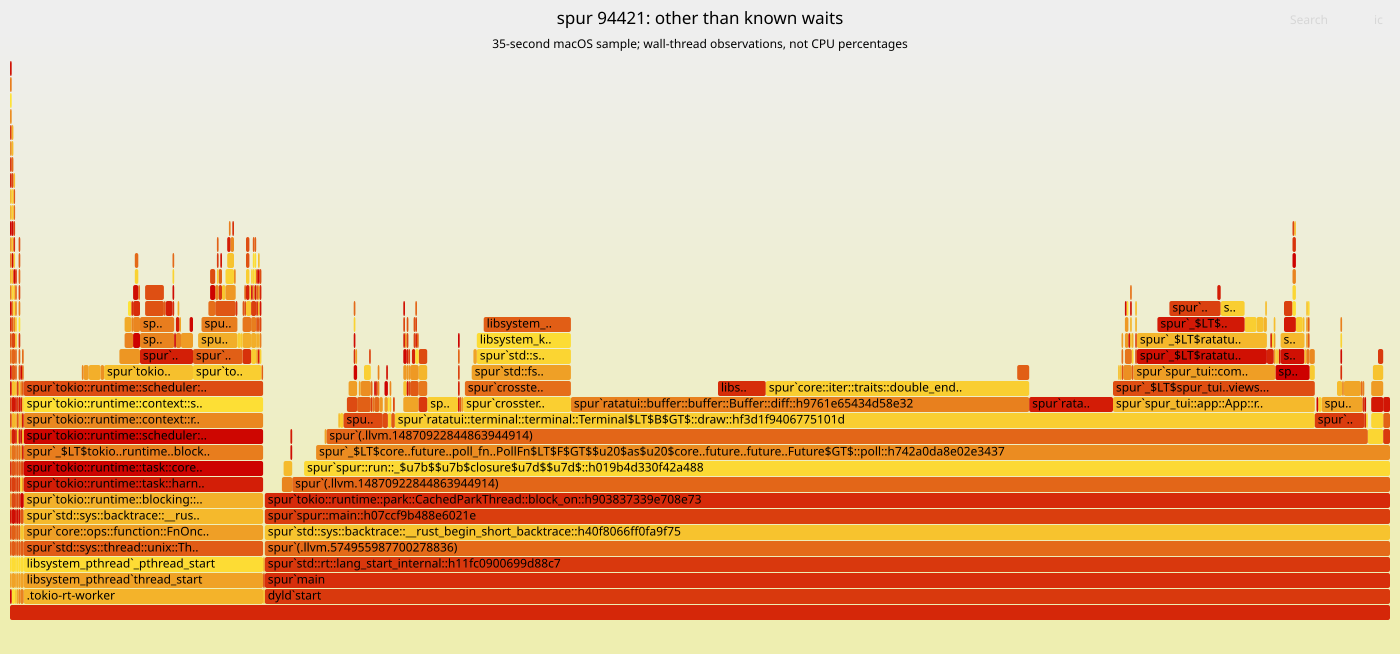

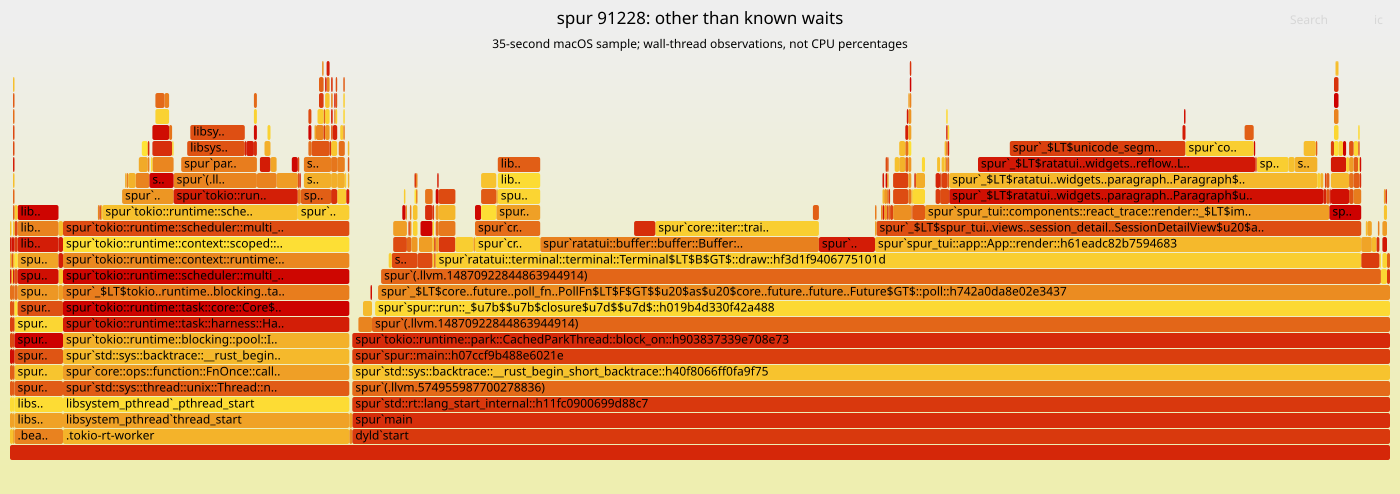

{'duckdb': '1.5.5',
 'extension': [{'extension_name': 'quack_flamegraph',
   'extension_version': '253fab9',
   'installed': True,
   'loaded': True}],
 'collapse_validation': [{'pid': 91228,
   'thread_roots': 37,
   'root_observations': 1064198,
   'folded_observations': 1064198,
   'nonzero_stacks': 309,
   'zero_parent_rows_omitted': 1017,
   'raw_sha256': 'ae4ebd71139b067f7a05a9873d961e921a7dd6adafb9261e5aff3c0eed3de585',
   'folded_sha256': '6204e7d2c866677c590d2f3823f8aec2d5a74464314f11520fadd41996346fec'},
  {'pid': 94421,
   'thread_roots': 50,
   'root_observations': 1406550,
   'folded_observations': 1406550,
   'nonzero_stacks': 316,
   'zero_parent_rows_omitted': 1188,
   'raw_sha256': '0a9aaad742dd954e873b6f9cac537b86b7c7e5f17f20a084382bb4cbbbe71732',
   'folded_sha256': 'cb2d13b9ed32ebceb08ac6b2b2f3f5fcfe4c338bd884cd3db3a13b5bfea2f7d2'}],
 'cpu_unit_validation': {'python_process_cpu_seconds': 0.200001,
  'converted_rusage_cpu_seconds': 0.20001454166666666,
  'mach_numer'

In [11]:
import json, re, subprocess
from pathlib import Path
import duckdb
from IPython.display import SVG, display

profile_root = Path('/Users/kevintruong/project/SpurCode/docs/research/2026-10-27-spur-process-performance')
validation = json.loads((profile_root / 'collapse-validation.json').read_text())
cpu_validation = json.loads((profile_root / 'cpu-unit-validation.json').read_text())
assert cpu_validation['relative_error'] < 0.05
counts = dict(duckdb.sql('SELECT pid, sum(samples) FROM spur_profile_stacks GROUP BY pid').fetchall())
for item in validation:
    assert counts[item['pid']] == item['root_observations'] == item['folded_observations']

def records(query):
    result = duckdb.sql(query)
    columns = [c[0] for c in result.description]
    return [dict(zip(columns, row)) for row in result.fetchall()]

summary = {
    'duckdb': duckdb.__version__,
    'extension': records("SELECT extension_name, extension_version, installed, loaded FROM duckdb_extensions() WHERE extension_name = 'quack_flamegraph'"),
    'collapse_validation': validation,
    'cpu_unit_validation': cpu_validation,
    'profile_summary': records("""
        SELECT pid, sum(samples)::BIGINT AS observations,
        sum(samples) FILTER (WHERE wait_like_leaf)::BIGINT AS wait_like,
        sum(samples) FILTER (WHERE NOT wait_like_leaf)::BIGINT AS other,
        sum(samples) FILTER (WHERE beads_writer)::BIGINT AS writer,
        sum(samples) FILTER (WHERE beads_writer AND NOT wait_like_leaf)::BIGINT AS writer_other,
        sum(samples) FILTER (WHERE beads_writer AND lock_guard_setup)::BIGINT AS writer_lock_setup,
        sum(samples) FILTER (WHERE tui_frame AND NOT wait_like_leaf)::BIGINT AS tui_other
        FROM spur_profile_classified GROUP BY pid ORDER BY pid
    """),
    'scope': 'Live wall-stack samples; other than known waits is not equivalent to measured CPU time. No controlled before/after maintenance comparison.',
}
(profile_root / 'analysis-summary.json').write_text(json.dumps(summary, indent=2) + '\n')

for pid in [94421, 91228]:
    rows = duckdb.sql(f"SELECT frames, samples FROM spur_profile_classified WHERE pid={pid} AND NOT wait_like_leaf").fetchall()
    folded = ''.join(';'.join(frames) + ' ' + str(samples) + '\n' for frames, samples in rows)
    (profile_root / f'spur-{pid}.other.folded').write_text(folded)
    svg = subprocess.run(
        ['perl', str(profile_root / 'flamegraph.pl'), '--title', f'spur {pid}: other than known waits',
         '--subtitle', '35-second macOS sample; wall-thread observations, not CPU percentages',
         '--countname', 'observations', '--width', '1400'],
        input=folded, text=True, capture_output=True, check=True
    ).stdout
    (profile_root / f'spur-{pid}.svg').write_text(svg)
    display(SVG(svg))
display(summary)


## Findings

**No beads-maintenance bottleneck was visible in these two quiet live-process windows.** This is an observation, not an A/B estimate of the feature's incremental overhead.

| Metric | PID 94421 | PID 91228 |
|---|---:|---:|
| CPU during its own capture (one core = 100%) | 2.892% | 2.464% |
| CPU in counter-only window before sampling | 3.318% | 4.206% |
| CPU in counter-only window afterward | 1.821% | 2.000% |
| All-thread observations ending in known waits | 99.943% | 99.914% |
| Writer observations / other than known waits | 56,262 / 2 | 59,122 / 32 |
| TUI share of observations outside known waits | 70.4% | 68.4% |
| Physical footprint during capture | 3.016 GiB | 1.048 GiB |

The two processes show two beads writer stacks each. Their writer observations are over 99.9% known waits. The visible periodic writer work includes lock acquisition, a dirty-count query, and lock teardown. `MaintenanceRuntime` frames are inlined/unnamed in this optimized binary, so zero explicitly named maintenance samples must not be interpreted as zero maintenance cost.

**Concrete small cost:** `writer_loop → try_blocking_write_lock_once → WriteLockGuard::new → Command::output` accounts for 4 and 29 observations respectively. The current `write_lock.rs` source shows its `hostname()` fallback starts an external command when `HOSTNAME` is unset. This makes hostname lookup a possible small optimization target; these samples do not establish a user-visible regression or justify a larger refactor. Most visible non-wait activity is terminal buffer diffing, Unicode layout, and rendering.

**Memory deserves separate investigation if it is a concern:** physical footprint is approximately 3.0 GiB and 1.05 GiB, even though CPU is low. CPU stack sampling does not identify retained allocations or prove a leak.

**Limits:** no dirty-export workload was induced, no 15-minute filesystem sweep was deliberately triggered, and there is no controlled feature-disabled baseline. The first “before” window means before the profiler, not before maintenance was implemented. Samples include all threads and waits; do not convert their totals to CPU seconds. Observed disk-write deltas were zero, which does not prove there were no logical writes. The existing optimized binary's UUID matches the live processes and contains maintenance markers; it is not a reproducible build attestation for a specific commit.

CPU counters were converted from Mach ticks with the host's 125/3 timebase and checked against an independent 0.2-second process-CPU measurement (relative error below 0.01%). Stack collapse conserves every thread-root observation. The two SVGs above intentionally exclude known wait leaf functions, and their percentages describe that filtered set—not total process CPU.

Artifacts are in the sibling `2026-10-27-spur-process-performance/` directory, including raw samples, full folded stacks, counters, validation receipts, analysis JSON, and SVG flamegraphs.